In [236]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import(
    confusion_matrix,
    recall_score,
    precision_score,
    f1_score,
    accuracy_score,
    classification_report
)


In [237]:
data = load_breast_cancer()
X_full= data.data
y_full=data.target

print('feature:', X_full.shape)
print('target:', y_full.shape)

feature: (569, 30)
target: (569,)


In [238]:
#create DataFrame , data and feature name
feature_names=data.feature_names
df=pd.DataFrame(X_full, columns=feature_names)
df['target']=y_full
df.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


In [239]:
df.describe().T.head(5)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634


In [240]:
df["target"].value_counts()

,count
target,
1,357
0,212


In [241]:
#train test slit
X_train, X_test, y_train, y_test =train_test_split( X_full, y_full, test_size=0.2, random_state=42, stratify=y_full)

#standarscale
scaler= StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [242]:
#model train
clf = LogisticRegression(max_iter=100)
clf.fit(X_train_scaled, y_train)

#predict
y_train_pred=clf.predict(X_train_scaled)
y_test_pred=clf.predict(X_test_scaled)
#proba
y_test_proba= clf.predict_proba(X_test_scaled) [:,1]

print('accuracy',accuracy_score(y_test, y_test_pred))

accuracy 0.9824561403508771


In [243]:
#confusion matrix and classification  report
cm= confusion_matrix(y_test, y_test_pred)
print('confusion matrix\n',cm)

confusion matrix
 [[41  1]
 [ 1 71]]


In [244]:
#classification report
print('classification report\n',classification_report(y_test, y_test_pred))

classification report
               precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



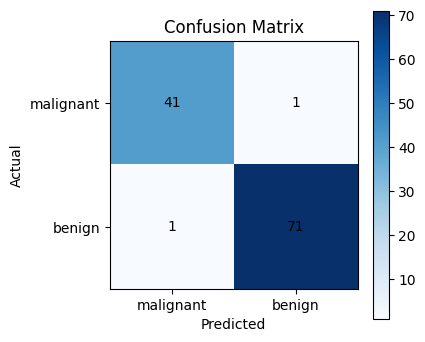

In [245]:
#visual confusion matrix
plt.figure(figsize=(4,4))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
ticks_labels=data.target_names
plt.xticks([0,1], ticks_labels)
plt.yticks([0,1], ticks_labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
#add value
for i in range(2):
  for j in range(2):
    plt.text(j,i,cm[i,j], ha='center', va='center', color='black')

#Evaluation Metrics and Threshold Effects

In [246]:
#basic evaluaton matrix with default threshold

acc=accuracy_score(y_test, y_test_pred)
rec=recall_score(y_test, y_test_pred)
prec=precision_score(y_test, y_test_pred)
f1=f1_score(y_test, y_test_pred)
print("Accuracy:", round(acc,2))
print("Precision:", round(prec,2))
print("Recall:", round(rec,2))
print("F1 score:", round(f1,2))


Accuracy: 0.98
Precision: 0.99
Recall: 0.99
F1 score: 0.99


In [247]:
## Try different thresholds and see how precision and recall change
thresholds= np.linspace(0.1, 0.9, 9)
rows=[]
for thr in thresholds:
  y_thr_pred=(y_test_proba >=thr).astype(int)
  acc_thr=accuracy_score(y_test, y_thr_pred)
  rec_thr=recall_score(y_test, y_thr_pred)
  prec_thr=precision_score(y_test, y_thr_pred)
  f1_thr=f1_score(y_test, y_thr_pred)
  rows.append([thr, acc_thr, prec_thr, rec_thr, f1_thr])
thr_df=pd.DataFrame(rows,columns=["threshold", "accuracy", "precision", "recall", "f1"])
thr_df

,threshold,accuracy,precision,recall,f1
0,0.1,0.956140,0.935065,1.000000,0.966443
1,0.2,0.982456,0.972973,1.000000,0.986301
2,0.3,0.982456,0.972973,1.000000,0.986301
3,0.4,0.982456,0.986111,0.986111,0.986111
4,0.5,0.982456,0.986111,0.986111,0.986111
5,0.6,0.956140,0.985507,0.944444,0.964539
6,0.7,0.947368,0.985294,0.930556,0.957143
7,0.8,0.938596,0.985075,0.916667,0.949640
8,0.9,0.894737,0.983871,0.847222,0.910448


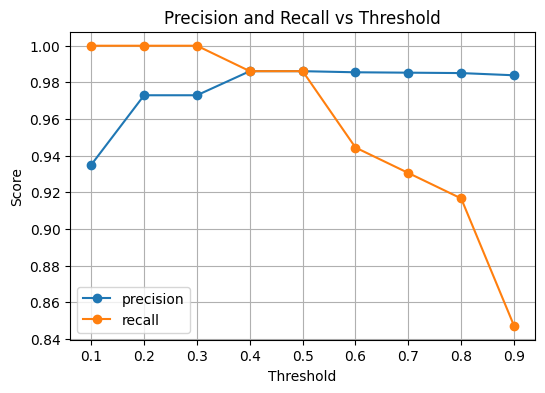

In [248]:
#plot precision and recall vs thresold
plt.figure(figsize=(6,4))
plt.plot(thr_df['threshold'],thr_df['precision'], marker='o', label='precision')
plt.plot(thr_df['threshold'],thr_df['recall'], marker='o', label='recall')
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Threshold")
plt.grid(True)
plt.legend()
plt.show()

#L2 Regularization

In [249]:
clf_week_reg= LogisticRegression(max_iter=100, C=100.0)
clf_strong_reg= LogisticRegression(max_iter=100, C=0.01)

clf_week_reg.fit(X_train_scaled, y_train)
clf_strong_reg.fit(X_train_scaled, y_train)

y_week_pred=clf_week_reg.predict(X_test_scaled)
y_strong_pred=clf_strong_reg.predict(X_test_scaled)

print("Weak reg (C=1000) test accuracy: ", accuracy_score(y_test, y_week_pred))
print("Strong reg (C=0.01) test accuracy: ", accuracy_score(y_test, y_strong_pred))

Weak reg (C=1000) test accuracy:  0.9473684210526315
Strong reg (C=0.01) test accuracy:  0.9473684210526315


In [251]:
# coefficient magnitudes
coef_weak = clf_week_reg.coef_[0]
coef_strong = clf_strong_reg.coef_[0]

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coef_weak_C_1000":coef_weak,
    "coef_strong_C_0.01":coef_strong
})

coef_df.head(15)

,feature,coef_weak_C_1000,coef_strong_C_0.01
0,mean radius,1.138232,-0.212316
1,mean texture,-1.525188,-0.180606
2,mean perimeter,0.800009,-0.209968
3,mean area,-0.780501,-0.196291
4,mean smoothness,-1.630507,-0.102438
5,mean compactness,11.465865,-0.098428
6,mean concavity,-4.199730,-0.149764
7,mean concave points,-2.014840,-0.206900
8,mean symmetry,-0.134265,-0.080873
9,mean fractal dimension,-3.846124,0.079728


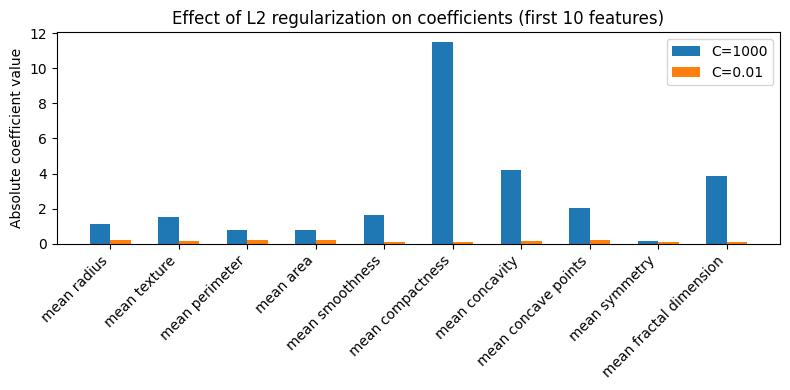

In [253]:
#plot absulate value for first 10
n_plot = 10
indices = np.arange(n_plot)
plt.figure(figsize=(8, 4))
plt.bar(indices - 0.15, np.abs(coef_weak[:n_plot]), width=0.3, label="C=1000")
plt.bar(indices + 0.15, np.abs(coef_strong[:n_plot]), width=0.3, label="C=0.01")
plt.xticks(indices, feature_names[:n_plot], rotation=45, ha="right")
plt.ylabel("Absolute coefficient value")
plt.title("Effect of L2 regularization on coefficients(first 10 feature)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#important library import
#dataset load and feature and target value, create dataframe
#info describe
#train test split
#standarscaler
#model train scaled data
#predict
#confusion matrix ans classification matrix
#vusual confusion matrix

#Section 4 – Evaluation Metrics and Threshold Effects
## Basic metrics at default threshold 0.5
## Try different thresholds and see how precision and recall change
# Plot precision and recall vs threshold

#l2
## Two models with different regularization strengths
# Compare coefficient magnitudes
#plot